# 03 · Score de Rescate aplicado, ROI simulado y Dashboard — DataByte / RescateAlimento
**Capstone · Etapas 3, 4 y 5 (dashboard, modelo de decisión, insights y ROI)**

## ¿Qué piden los apuntes y qué hacemos?
| Apunte | Acá |
|---|---|
| §3 *Reglas y heurísticas antes de modelar* → post-procesamiento → modelo | Ejecutamos el **mismo `modelo_score.py` del bot** (v02.7) sobre datos del proyecto y mostramos qué agrega frente a un semáforo por días. |
| §2 Elegir el modelo con una métrica | Reemplazamos el *ritmo* (media móvil) por la predicción del **modelo ML** del notebook 02 y medimos cuánto cambian las decisiones. |
| §5 **ROI simulado coherente con los datos** + 1 o 2 métricas de negocio + ahorro de tiempo | Simulación Monte Carlo lote por lote (usando la sensibilidad al precio y la merma medidas en el notebook 01) y ahorro de horas de trabajo. |
| §4 Dashboard manejable por el cliente | Panel de resultados + CSV listos para **Looker Studio**. |

> ⚠️ Igual que antes: los **datos son simulados** y los parámetros de costos/tiempos son **supuestos marcados** para reemplazar con mediciones reales
> (cronometrar, preguntar el costo hora y la merma del comercio). Los números de este notebook **no son resultados reales**: son un modelo para calcular el ROI en cuanto haya datos.

## 0. Configuración (usamos el código real del bot)

In [1]:
import sys, json, datetime, warnings
sys.path.insert(0, "bot_src")                 # copia de modelo_score.py, config.py, backend.py, logica_ventas.py, utils.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import config
import modelo_score as MS
from backend import clave_ean

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
SEED = 42

# Parámetros del Score: los mismos valores por defecto del bot (se pueden cambiar en el .env del bot).
config.DIAS_ROJO, config.DIAS_NARANJA = 3, 10
config.VENCE_AL_FINAL_DEL_DIA = True
config.VENTANA_RITMO_DIAS = 7
print("Pesos del Score → urgencia {:.0%} · ritmo {:.0%} · valor {:.0%} · precio {:.0%}".format(
    config.PESO_URGENCIA, config.PESO_RITMO, config.PESO_VALOR, config.PESO_PRECIO))

datos = pd.read_csv("data/dataset_modelado.csv", parse_dates=["fecha"], dtype={"telegram_id": str, "ean": str}).sort_values("fecha")
params = json.load(open("data/parametros.json"))
print("Fuente:", params["fuente"], "| sensibilidad al precio:", round(params["sensibilidad_precio"], 2),
      "| merma observada:", None if params["tasa_merma_observada"] is None else f"{params['tasa_merma_observada']:.1%}")

Pesos del Score → urgencia 40% · ritmo 25% · valor 20% · precio 15%
Fuente: SIMULADO | sensibilidad al precio: 1.99 | merma observada: 6.1%


## 1. Foto de hoy: lotes abiertos, historial y precios de la competencia
Armamos con los datos lo mismo que el bot lee de Google Sheets:
* `lotes` → pestaña **Lotes_Registrados** (stock que queda hoy, precio, vencimiento),
* `historial` → pestaña **Ventas_Registradas** (ventas de los últimos días),
* `maestro` → catálogo de la **competencia** que trae n8n (precio de lista).

In [2]:
HOY = datos.fecha.max()
ahora = datetime.datetime(HOY.year, HOY.month, HOY.day, 22, 0)      # cierre del día, ya cargadas las ventas de hoy

ult = datos[datos.fecha == HOY].copy()
ult["stock_hoy"] = ult.stock_inicial_dia - ult.unidades_vendidas
ult = ult[ult.stock_hoy > 0]
lotes = [{"id_lote": r.id_lote, "telegram_id": r.telegram_id, "ean": r.ean, "producto": r.producto, "marca": r.marca,
          "cantidad": int(r.stock_hoy), "precio_venta": float(r.precio_venta),
          "fecha_caducidad": (HOY + pd.Timedelta(days=int(r.dias_al_vencimiento))).strftime("%Y-%m-%d")}
         for r in ult.itertuples()]

# Historial en el formato de Ventas_Registradas (el bot lo pasa por MS.normalizar_historial).
ventas_ult = datos[(datos.fecha > HOY - pd.Timedelta(days=28)) & (datos.unidades_vendidas > 0)]
historial = MS.normalizar_historial([
    {"telegram_id": r.telegram_id, "ean": r.ean, "cantidad_unitarias": r.unidades_vendidas,
     "fecha_vendido": r.fecha.strftime("%Y-%m-%d")} for r in ventas_ult.itertuples()])

# Catálogo de la competencia: precio de lista de hoy por EAN.
ref = ult.groupby("ean").precio_competencia.last()
maestro = {clave_ean(e): {"precio_lista": float(p), "precio_min": float(p) * 0.8} for e, p in ref.items()}
print(f"{len(lotes)} lotes abiertos · {len(historial):,} registros de venta · {len(maestro)} EAN con precio de competencia")

36 lotes abiertos · 998 registros de venta · 12 EAN con precio de competencia


## 2. Score de Rescate (heurística + reglas de negocio) — exactamente el del bot
`MS.ranking()` es la función que llama el botón *3. Score de Rescate* de Telegram. Acá la usamos con los 3 comercios.

In [3]:
def ranking_todos(historial_):
    filas = []
    for tid in sorted({l["telegram_id"] for l in lotes}):
        for f in MS.ranking(lotes, tid, maestro, historial_, ahora):
            filas.append({**f, "telegram_id": tid, "accion_texto": MS.ACCIONES[f["accion"]]})
    return pd.DataFrame(filas)

score = ranking_todos(historial)
print(f"Lotes evaluados: {len(score)}")
cols = ["telegram_id","ranking","producto","cantidad","precio_actual","dias_restantes","ritmo_diario","merma_proyectada",
        "score","nivel","accion","precio_sugerido","descuento_sugerido_pct"]
display(score[score.telegram_id == "1002"][cols].head(12))

Lotes evaluados: 36


,telegram_id,ranking,producto,cantidad,precio_actual,dias_restantes,ritmo_diario,merma_proyectada,score,nivel,accion,precio_sugerido,descuento_sugerido_pct
12,1002,1,Pan Lactal 500 g,15,2721.11,0,10.57,4.4,64.7,NARANJA,BAJAR,1278.00,53.0
13,1002,2,Jamon Cocido 200 g,76,3818.77,7,6.57,23.4,61.6,NARANJA,BAJAR,2476.56,35.1
14,1002,3,Medialunas x6,24,3305.10,2,7.00,3.0,60.8,NARANJA,BAJAR,1735.09,47.5
15,1002,4,Leche Entera 1 L,92,1498.79,7,14.43,0.0,52.5,NARANJA,BAJAR,984.22,34.3
16,1002,5,Pollo Entero kg,27,3000.60,4,7.43,0.0,46.4,NARANJA,BAJAR,2376.70,20.8
17,1002,6,Queso Cremoso 500 g,72,4499.05,13,3.57,22.0,44.9,NARANJA,BAJAR,3802.21,15.5
18,1002,7,Yogur Entero 1 L,101,2042.24,15,11.29,0.0,33.0,VERDE,MANTENER,NaN,NaN
19,1002,8,Hamburguesas Swift 4 Un,101,8044.61,21,3.86,16.1,25.6,VERDE,MANTENER,NaN,NaN
20,1002,9,Hamburguesas Paty 2 Un,161,2467.81,36,8.57,0.0,20.1,VERDE,MANTENER,NaN,NaN
21,1002,10,Gaseosa 2.25 L,203,2695.91,79,12.14,0.0,20.0,VERDE,MANTENER,NaN,NaN


### 2.1 ¿Cómo se reparten los lotes y las acciones?

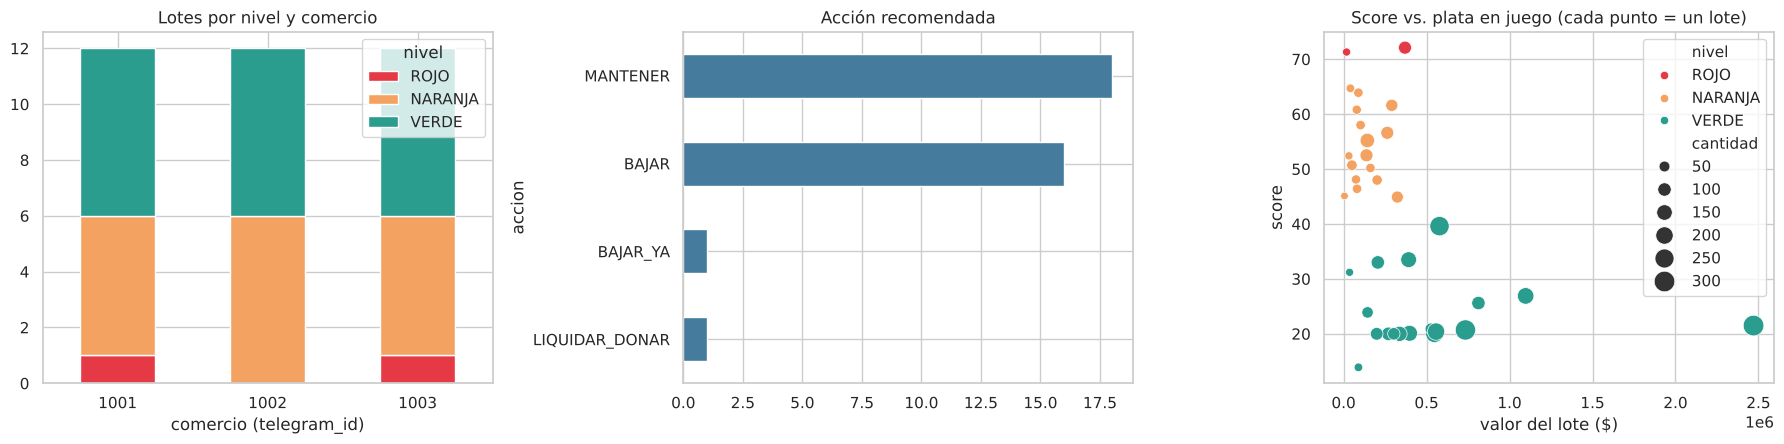

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
orden = ["ROJO","NARANJA","VERDE"]; pal = {"ROJO": "#e63946", "NARANJA": "#f4a261", "VERDE": "#2a9d8f"}
(score.groupby(["telegram_id","nivel"]).size().unstack(fill_value=0).reindex(columns=orden)
      .plot.bar(stacked=True, ax=ax[0], color=[pal[c] for c in orden], rot=0))
ax[0].set_title("Lotes por nivel y comercio"); ax[0].set_xlabel("comercio (telegram_id)")
score.accion.value_counts().plot.barh(ax=ax[1], color="#457b9d"); ax[1].set_title("Acción recomendada"); ax[1].invert_yaxis()
sns.scatterplot(data=score, x="valor_en_riesgo", y="score", hue="nivel", palette=pal, size="cantidad", sizes=(30, 220), ax=ax[2])
ax[2].set_title("Score vs. plata en juego (cada punto = un lote)"); ax[2].set_xlabel("valor del lote ($)")
plt.tight_layout(); plt.show()

### 2.2 ¿Qué agrega el Score frente a un semáforo solo por días?
El stock "Ver Stock Actual" (v02.6) ya usa un semáforo por **días al vencimiento**. Si el Score diera lo mismo no valdría la pena.
Cruzamos ambos: las celdas fuera de la diagonal son lotes donde **el Score decide distinto** porque mira también el ritmo de venta, el valor y el precio de la competencia.

In [5]:
score["semaforo_dias"] = np.where(score.dias_restantes <= config.DIAS_ROJO, "ROJO",
                          np.where(score.dias_restantes <= config.DIAS_NARANJA, "NARANJA", "VERDE"))
cruce = pd.crosstab(score.semaforo_dias, score.nivel).reindex(index=orden, columns=orden, fill_value=0)
display(cruce.rename_axis("Semáforo por días ↓ / Nivel del Score →"))
difieren = (score.semaforo_dias != score.nivel).mean()
print(f"El Score decide distinto del semáforo por días en {difieren:.0%} de los lotes.")
ejemplo = score[(score.semaforo_dias == "VERDE") & (score.nivel != "VERDE")].head(5)
print("\nEjemplos de lotes 'verdes por días' que el Score marca como atención (venden lento o son mucha plata):")
display(ejemplo[["producto","dias_restantes","cantidad","ritmo_diario","merma_proyectada","score","nivel","accion"]])

nivel,ROJO,NARANJA,VERDE
Semáforo por días ↓ / Nivel del Score →,,,
ROJO,1,7,0
NARANJA,1,8,1
VERDE,0,1,17


El Score decide distinto del semáforo por días en 28% de los lotes.

Ejemplos de lotes 'verdes por días' que el Score marca como atención (venden lento o son mucha plata):


,producto,dias_restantes,cantidad,ritmo_diario,merma_proyectada,score,nivel,accion
17,Queso Cremoso 500 g,13,72,3.57,22.0,44.9,NARANJA,BAJAR


## 3. ¿Qué pasa si el *ritmo* lo predice el modelo ML? (notebook 02)
Hoy el Score estima el ritmo con la **media móvil de 7 días**. Acá usamos el modelo entrenado (`models/modelo_demanda.joblib`)
para predecir las ventas de **mañana** de cada lote y se lo pasamos al mismo Score como si fuera el ritmo.
Construimos las variables de mañana con **exactamente las mismas definiciones** del notebook 01 (ayer, hace 7 días, medias móviles 7 y 28).

In [6]:
info = json.load(open("models/modelo_demanda.json"))
modelo = joblib.load("models/modelo_demanda.joblib")
print(f"Modelo cargado: {info['modelo']} (MAE test {info['mae_test']:.2f} vs media móvil {info['mae_media_movil']:.2f}) · veredicto: {info['veredicto']}")

manana = HOY + pd.Timedelta(days=1)
filas = []
for l in lotes:
    s = datos[(datos.telegram_id == l["telegram_id"]) & (datos.ean == l["ean"])].set_index("fecha").unidades_vendidas
    dias_hoy = (pd.to_datetime(l["fecha_caducidad"]) - HOY).days
    filas.append({
        "id_lote": l["id_lote"], "telegram_id": l["telegram_id"], "ean": l["ean"],
        "categoria": datos[datos.ean == l["ean"]].categoria.iloc[0],
        "precio_rel": l["precio_venta"] / maestro[clave_ean(l["ean"])]["precio_lista"],
        "dias_al_vencimiento": max(dias_hoy - 1, 0), "stock_inicial_dia": l["cantidad"],
        "dow": manana.dayofweek, "es_finde": int(manana.dayofweek in (4, 5, 6)), "dia_mes": manana.day,
        "ventas_lag1": s.iloc[-1], "ventas_lag7": s.iloc[-7],
        "media_movil_7": s.iloc[-7:].mean(), "media_movil_28": s.iloc[-28:].mean()})
X_man = pd.DataFrame(filas)
X_man["ritmo_ml"] = np.clip(modelo.predict(X_man[info["numericas"] + info["categoricas"]]), 0, None)
X_man["ritmo_mm7"] = X_man.media_movil_7
display(X_man[["telegram_id","ean","ritmo_mm7","ritmo_ml"]].describe().round(2))

# Se lo inyectamos al Score como un historial "sintético" de 7 días con ese ritmo constante.
hist_ml = []
for r in X_man.itertuples():
    for k in range(7):
        hist_ml.append({"telegram_id": r.telegram_id, "ean": r.ean, "cantidad": float(r.ritmo_ml),
                        "fecha": (HOY - pd.Timedelta(days=k)).date()})
score_ml = ranking_todos(hist_ml)

Modelo cargado: Gradient Boosting (MAE test 2.58 vs media móvil 3.04) · veredicto: INTEGRAR


,ritmo_mm7,ritmo_ml
count,36.00,36.00
mean,8.66,7.79
std,5.41,4.96
min,2.00,2.48
25%,5.04,4.35
50%,7.57,6.72
75%,11.07,10.63
max,27.86,26.66


Con el ritmo del ML cambia el NIVEL en 8% de los lotes y la ACCIÓN en 8%.
Merma proyectada total: media móvil 203 un. vs ML 284 un.


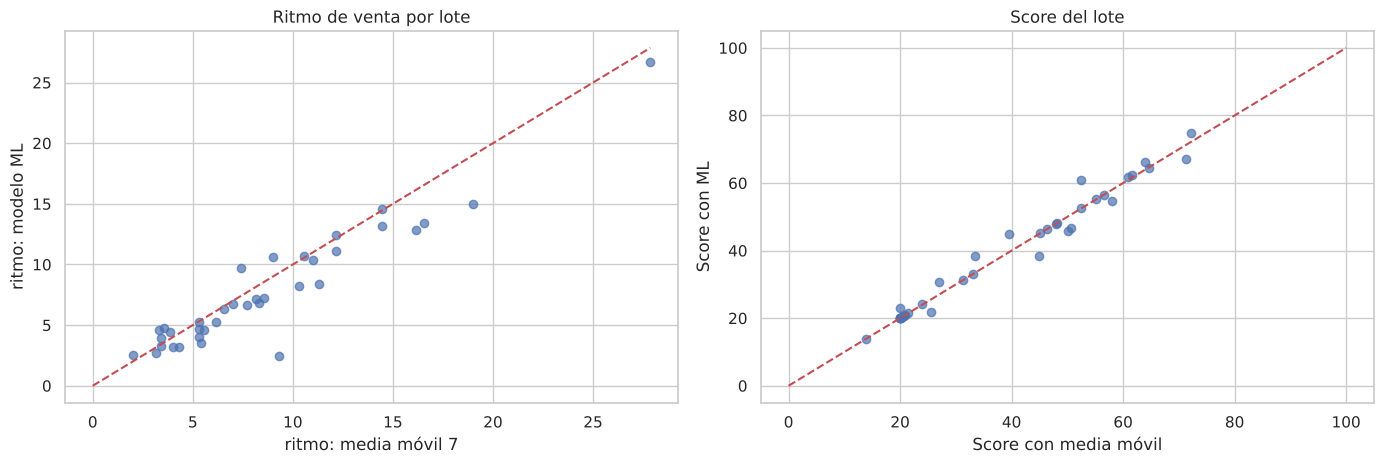

,producto,ritmo_diario_mm7,ritmo_diario_ml,nivel_mm7,nivel_ml,accion_mm7,accion_ml
6,Yogur Entero 1 L,16.14,12.86,VERDE,NARANJA,MANTENER,BAJAR
17,Queso Cremoso 500 g,3.57,4.73,NARANJA,VERDE,BAJAR,MANTENER
24,Yogur Entero 1 L,3.29,4.57,ROJO,NARANJA,LIQUIDAR_DONAR,BAJAR


In [7]:
comp = score[["id_lote","producto","telegram_id","ritmo_diario","merma_proyectada","score","nivel","accion"]].merge(
       score_ml[["id_lote","ritmo_diario","merma_proyectada","score","nivel","accion"]], on="id_lote", suffixes=("_mm7", "_ml"))
cambio_nivel = (comp.nivel_mm7 != comp.nivel_ml).mean()
cambio_accion = (comp.accion_mm7 != comp.accion_ml).mean()
print(f"Con el ritmo del ML cambia el NIVEL en {cambio_nivel:.0%} de los lotes y la ACCIÓN en {cambio_accion:.0%}.")
print(f"Merma proyectada total: media móvil {comp.merma_proyectada_mm7.sum():.0f} un. vs ML {comp.merma_proyectada_ml.sum():.0f} un.")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].scatter(comp.ritmo_diario_mm7, comp.ritmo_diario_ml, alpha=.7); m = max(comp.ritmo_diario_mm7.max(), comp.ritmo_diario_ml.max())
ax[0].plot([0, m], [0, m], "r--"); ax[0].set_xlabel("ritmo: media móvil 7"); ax[0].set_ylabel("ritmo: modelo ML"); ax[0].set_title("Ritmo de venta por lote")
ax[1].scatter(comp.score_mm7, comp.score_ml, alpha=.7); ax[1].plot([0, 100], [0, 100], "r--")
ax[1].set_xlabel("Score con media móvil"); ax[1].set_ylabel("Score con ML"); ax[1].set_title("Score del lote")
plt.tight_layout(); plt.show()
display(comp[comp.accion_mm7 != comp.accion_ml][["producto","ritmo_diario_mm7","ritmo_diario_ml","nivel_mm7","nivel_ml","accion_mm7","accion_ml"]].head(8))

**Cómo leerlo:** el ML y la media móvil casi siempre coinciden (puntos sobre la diagonal); donde difieren, el ML incorpora el **día de la semana, el precio relativo y el stock**.
En los lotes con cambio de acción es donde el ML aporta (o equivoca). Con datos reales conviene revisar a mano esos casos antes de reemplazar la heurística.

## 4. ROI: simulación coherente con los datos (apuntes §5)
> *"Como no hay pruebas en producción, se puede simular el ROI usando datos internos del negocio y estadísticas del mercado; la simulación debe ser coherente con los datos reales."*

### 4.1 Idea
Tomamos **lotes del dataset** (cantidad, vida útil, costo, demanda de su comercio-producto) y los vendemos **varias veces** en el simulador, día por día:
* **Política A — "sin bot"**: el comercio mantiene el precio y recién en los **últimos 2 días** lo rebaja 20 % (hábito típico; *supuesto editable*).
* **Política B — "Score v02.7 tal cual"**: cada día se corre `MS.calcular_lote()` (el código del bot) con el stock restante y las ventas de los últimos 7 días simuladas hasta ese momento, y se aplica el **precio sugerido**. Si la acción es *LIQUIDAR_DONAR* se liquida al mínimo.
* **Política C — "Score calibrado"** *(la mejora que surge de este análisis, ver 4.5)*: usa el mismo ritmo de venta pero **solo rebaja lo necesario para vender el lote antes de que venza**, calculando el precio con la **sensibilidad al precio medida en el notebook 01**, y no baja de un **precio piso** (costo).
* **Adherencia**: no todos los comerciantes siguen la recomendación; se simula la fracción que sí (30 % / 60 % / 90 %).

La reacción de la demanda al precio usa la sensibilidad estimada con los datos: `ventas ∝ (precio / precio_competencia)^(−sensibilidad)`.

### 4.2 Supuestos que hay que reemplazar por mediciones reales
Están todos juntos en la celda siguiente, marcados con `# SUPUESTO`.

In [8]:
# ============================ SUPUESTOS (reemplazar por mediciones reales) ============================
A_DIAS_ULTIMO_MOMENTO = 2      # SUPUESTO: sin bot, el comerciante rebaja recién en los últimos 2 días...
A_DESCUENTO           = 0.20   # SUPUESTO: ...y lo hace con 20 % de descuento
LIQUIDACION_DESC      = config.DESCUENTO_TOPE   # B, LIQUIDAR_DONAR: precio mínimo = tope del modelo (65 % off)
PISO_MARGEN           = 0.0    # SUPUESTO (política C): precio piso = costo × (1 + margen). Por debajo de eso se dona
N_REPETICIONES        = 5      # veces que se repite la simulación con distinto azar (promedia el ruido)

# Ahorro de tiempo (cronometrar con el comerciante y reemplazar):
MIN_CARGA_MANUAL_POR_LOTE = 3.0    # SUPUESTO: minutos para anotar un lote a mano en planilla
MIN_CARGA_BOT_POR_LOTE    = 1.0    # SUPUESTO: minutos para cargarlo con el bot (foto/factura)
MIN_REVISION_DIARIA_MANUAL = 20.0  # SUPUESTO: minutos por día mirando vencimientos y decidiendo precios
MIN_REVISION_DIARIA_BOT    = 3.0   # SUPUESTO: minutos por día leyendo el Score
VALOR_HORA                 = 5000.0  # SUPUESTO: $ por hora de trabajo en el rubro (completar con dato real)
COSTO_MENSUAL_HERRAMIENTAS = 40000.0 # SUPUESTO: $ por mes (n8n, hosting, API de visión). Completar con facturas reales.
# =====================================================================================================
SENSIBILIDAD = params["sensibilidad_precio"]      # medida con los datos (notebook 01)
print("Sensibilidad al precio usada:", round(SENSIBILIDAD, 2))

Sensibilidad al precio usada: 1.99


In [9]:
# Parámetros de demanda de cada serie (comercio-producto), estimados con los datos.
datos["rel_pot"] = datos.precio_rel ** (-SENSIBILIDAD)
serie = datos.groupby(["telegram_id", "ean"]).agg(media=("unidades_vendidas", "mean"), pot=("rel_pot", "mean"))
serie["lam0"] = serie.media / serie.pot                        # ventas/día esperadas con precio = competencia
pref_ean = datos.groupby("ean").precio_competencia.median()

lotes_sim = pd.read_csv("data/lotes_simulados.csv", parse_dates=["fecha_ingreso", "fecha_vencimiento"],
                        dtype={"telegram_id": str, "ean": str})
lotes_sim = lotes_sim[lotes_sim.cerrado].reset_index(drop=True)
lotes_sim["dias_vida"] = (lotes_sim.fecha_vencimiento - lotes_sim.fecha_ingreso).dt.days
print(f"{len(lotes_sim)} lotes cerrados disponibles para simular")

def vender_lote(l, politica, adherente, s, rng):
    # Simula la vida de UN lote día por día con la política indicada ("A", "B" o "C").
    # Devuelve (unidades vendidas, ingresos, unidades sin vender al vencer).
    pref = float(pref_ean[l.ean]); lam0 = float(serie.loc[(l.telegram_id, l.ean), "lam0"])
    stock, precio = int(l.cantidad_inicial), float(l.precio_base)
    ingresos, vendidas_tot = 0.0, 0
    maestro_lote = {clave_ean(l.ean): {"precio_lista": pref, "precio_min": pref * .8}}
    hist, obs = [], []                                         # historial simulado de este lote (arranque en frío)
    for k in range(-7, 0):
        v = float(rng.poisson(lam0))
        hist.append({"telegram_id": l.telegram_id, "ean": l.ean, "cantidad": v, "fecha": (l.fecha_ingreso + pd.Timedelta(days=k)).date()})
        obs.append((v, pref))                                  # (unidades vendidas, precio al que se vendieron)
    for k in range(int(l.dias_vida) + 1):
        dias_rest = int(l.dias_vida) - k
        fecha = l.fecha_ingreso + pd.Timedelta(days=k)
        if adherente and politica == "B":                      # el Score v02.7 tal cual
            lote = {"id_lote": l.id_lote, "telegram_id": l.telegram_id, "ean": l.ean, "producto": l.producto,
                    "marca": "", "cantidad": stock, "precio_venta": precio,
                    "fecha_caducidad": l.fecha_vencimiento.strftime("%Y-%m-%d")}
            r = MS.calcular_lote(lote, maestro_lote, hist, datetime.datetime(fecha.year, fecha.month, fecha.day, 8, 0))
            if r:
                if r["accion"] in ("BAJAR_YA", "BAJAR") and r["precio_sugerido"]:
                    precio = min(precio, r["precio_sugerido"])
                elif r["accion"] == "LIQUIDAR_DONAR":
                    precio = min(precio, pref * (1 - LIQUIDACION_DESC))
        elif adherente and politica == "C":                    # Score calibrado: rebajar SOLO lo necesario
            ritmo_ref = np.mean([v * (p / pref) ** s for v, p in obs[-7:]])      # ritmo "limpio" a precio de referencia
            necesario = stock / (dias_rest + 1)                                  # unidades/día para no tener merma
            if ritmo_ref > 0 and ritmo_ref * (precio / pref) ** (-s) < necesario:
                p_obj = pref * (necesario / ritmo_ref) ** (-1 / s)               # precio que (en promedio) lo vende todo
                piso = max(float(l.costo) * (1 + PISO_MARGEN), pref * (1 - config.DESCUENTO_TOPE))
                precio = min(precio, max(p_obj, piso))
        elif dias_rest <= A_DIAS_ULTIMO_MOMENTO:               # política A (o B/C sin adherencia)
            precio = min(precio, float(l.precio_base) * (1 - A_DESCUENTO))
        lam = lam0 * (precio / pref) ** (-s)
        v = int(min(rng.poisson(lam), stock))
        stock -= v; ingresos += v * precio; vendidas_tot += v
        hist.append({"telegram_id": l.telegram_id, "ean": l.ean, "cantidad": float(v), "fecha": fecha.date()}); obs.append((float(v), precio))
        if stock == 0: break
    return vendidas_tot, ingresos, stock

def simular(adherencia, s, bot="C", n=None, seed=SEED, reps=N_REPETICIONES):
    # Corre A y la política `bot` sobre los lotes, repitiendo `reps` veces con distinto azar (las ventas son aleatorias,
    # y con pocos lotes un resultado aislado engaña). n=None usa todos los lotes cerrados.
    filas = []
    for r in range(reps):
        sd = seed + 100_000 * r
        muestra = lotes_sim if n is None else lotes_sim.sample(min(n, len(lotes_sim)), random_state=sd)
        for i, l in enumerate(muestra.itertuples()):
            adh = np.random.default_rng(sd + 10_000 + i).random() < adherencia    # ¿este comerciante sigue el Score?
            a = vender_lote(l, "A", False, s, np.random.default_rng(sd + i))      # mismos números aleatorios en A y bot
            b = vender_lote(l, bot, adh, s, np.random.default_rng(sd + i))
            costo_lote = l.costo * l.cantidad_inicial
            filas.append({"id_lote": l.id_lote, "cantidad": l.cantidad_inicial, "costo_unit": l.costo,
                          "vend_A": a[0], "ing_A": a[1], "merma_A": a[2], "vend_B": b[0], "ing_B": b[1], "merma_B": b[2],
                          "ganancia_A": a[1] - costo_lote, "ganancia_B": b[1] - costo_lote})
    return pd.DataFrame(filas)

import time; t0 = time.time()
simular(0.6, SENSIBILIDAD, n=60, reps=1)
print(f"Prueba rápida OK ({time.time()-t0:.1f}s para 60 lotes)")

364 lotes cerrados disponibles para simular
Prueba rápida OK (0.1s para 60 lotes)


### 4.3 Chequeo de coherencia
Antes de creerle al ROI, comprobamos que la política **A** (sin bot) reproduce una merma parecida a la **observada** en los datos (notebook 01).
Si el simulador diera una merma totalmente distinta, el ROI estaría construido sobre arena.

In [10]:
base = simular(0.0, SENSIBILIDAD)          # adherencia 0 → el bot no cambia nada; sirve para medir la merma de A
merma_A = base.merma_A.sum() / base.cantidad.sum()
print(f"Merma simulada sin bot (política A): {merma_A:.1%}")
if params["tasa_merma_observada"] is not None:
    print(f"Merma observada en los datos       : {params['tasa_merma_observada']:.1%}")
    print("→ Misma magnitud: el simulador es razonable." if abs(merma_A - params["tasa_merma_observada"]) < 0.05
          else "→ ⚠️ Magnitudes distintas: revisar supuestos A_* antes de usar el ROI.")

Merma simulada sin bot (política A): 6.3%
Merma observada en los datos       : 6.1%
→ Misma magnitud: el simulador es razonable.


### 4.4 Primer resultado: el Score v02.7 *tal cual* (política B)
Simulamos que **todos** los comerciantes siguen el Score actual al pie de la letra. Miramos dos cosas: la **merma** (que debería bajar) y la **ganancia** (que debería subir).

In [11]:
dB = simular(1.0, SENSIBILIDAD, bot="B")
cant = dB.cantidad.sum()
print(f"Merma:    sin bot {100*dB.merma_A.sum()/cant:.1f} %  →  con Score v02.7 {100*dB.merma_B.sum()/cant:.1f} %")
print(f"Ganancia por lote: sin bot ${dB.ganancia_A.mean():,.0f}  →  con Score v02.7 ${dB.ganancia_B.mean():,.0f}   (diferencia ${(dB.ganancia_B-dB.ganancia_A).mean():,.0f})")

dB["grupo"] = np.where(dB.merma_A > 0, "Lotes que SÍ iban a tener merma", "Lotes que se vendían igual")
diag = dB.groupby("grupo").agg(lotes=("id_lote", "count"), merma_sin_bot=("merma_A", "sum"), merma_con_score=("merma_B", "sum"),
                               ganancia_extra_por_lote=("ganancia_B", "mean"))
diag["ganancia_extra_por_lote"] = dB.groupby("grupo").apply(lambda g: (g.ganancia_B - g.ganancia_A).mean())
display(diag.round(0))

Merma:    sin bot 6.3 %  →  con Score v02.7 0.0 %
Ganancia por lote: sin bot $68,495  →  con Score v02.7 $31,765   (diferencia $-36,730)


,lotes,merma_sin_bot,merma_con_score,ganancia_extra_por_lote
grupo,,,,
Lotes que SÍ iban a tener merma,636,12296,0,-29328.0
Lotes que se vendían igual,1184,0,0,-40705.0


### 🔎 Hallazgo importante (el tipo de insight que pide la Etapa 5)
El Score v02.7 **sí reduce la merma**, pero en la simulación **pierde plata** frente a "no hacer nada": recomienda descuentos grandes
**aunque el lote se iba a vender igual** (el descuento sale de la *urgencia* y del precio de la competencia, no de si el lote realmente va a sobrar).
Ejemplo real del notebook (sección 2): *Leche 1 L, 92 unidades, 7 días, ritmo 14/día → merma proyectada 0* y sin embargo el Score sugiere bajar de $1.499 a $984.

Esto **no invalida el proyecto**: es justo lo que sirve para mejorar el modelo. El ROI debe medir **ganancia**, no solo merma evitada.

### 4.5 La mejora: Score calibrado con elasticidad (política C)
Regla: *"rebajá solo lo necesario para vender todo antes de que venza, y no pases del costo"*.
1. `necesario` = unidades/día que hay que vender para no tener merma = `stock / días de venta que quedan`.
2. Si el ritmo actual ya alcanza → **no se rebaja** (mantener precio).
3. Si no alcanza → se calcula el precio que acerca el ritmo al necesario usando la sensibilidad medida: `precio = referencia × (necesario / ritmo)^(−1/sensibilidad)`.
4. Se limita por el **precio piso** (costo) y por el tope de descuento (65 %). Lo que no se pueda vender sobre el costo se **dona**.

Es el mismo Score (mismo ritmo, mismas alertas), pero con un **precio sugerido basado en datos**. Se podría llevar al bot como `v02.8` (requiere guardar el costo del lote, que ya viene en la factura).

In [12]:
dC = simular(1.0, SENSIBILIDAD, bot="C")
comparacion = pd.DataFrame({
    "Sin bot (A)":          [100*dC.merma_A.sum()/cant, dC.ganancia_A.mean(), 0.0],
    "Score v02.7 (B)":      [100*dB.merma_B.sum()/cant, dB.ganancia_B.mean(), (dB.ganancia_B - dB.ganancia_A).mean()],
    "Score calibrado (C)":  [100*dC.merma_B.sum()/cant, dC.ganancia_B.mean(), (dC.ganancia_B - dC.ganancia_A).mean()],
}, index=["merma %", "ganancia media por lote $", "ganancia extra por lote vs. sin bot $"]).round(1)
display(comparacion)
print("Unidades sin vender (candidatas a donación): A", int(dC.merma_A.sum()), "| B", int(dB.merma_B.sum()), "| C", int(dC.merma_B.sum()))

,Sin bot (A),Score v02.7 (B),Score calibrado (C)
merma %,6.3,0.0,0.4
ganancia media por lote $,68495.1,31765.5,69453.6
ganancia extra por lote vs. sin bot $,0.0,-36729.6,958.5


Unidades sin vender (candidatas a donación): A 12296 | B 0 | C 731


### 4.6 Escenarios de ROI (con el Score calibrado y también con el v02.7 para comparar)
| Escenario | Adherencia (¿cuántos siguen el Score?) | Sensibilidad al precio |
|---|---|---|
| Conservador | 30 % | 75 % de la medida |
| Base | 60 % | la medida |
| Optimista | 90 % | 125 % de la medida |

In [13]:
ESCENARIOS = {"Conservador": (0.30, SENSIBILIDAD * 0.75), "Base": (0.60, SENSIBILIDAD), "Optimista": (0.90, SENSIBILIDAD * 1.25)}
lotes_mes = params["lotes_mes_por_comercio"] or 30        # lotes que mueve un comercio por mes (medido en notebook 01)
dias_mes = 30
horas_ahorro = (lotes_mes * (MIN_CARGA_MANUAL_POR_LOTE - MIN_CARGA_BOT_POR_LOTE)
                + dias_mes * (MIN_REVISION_DIARIA_MANUAL - MIN_REVISION_DIARIA_BOT)) / 60
beneficio_tiempo = horas_ahorro * VALOR_HORA

def tabla_roi(bot):
    filas, sims = [], {}
    for nombre, (adh, s) in ESCENARIOS.items():
        df = simular(adh, s, bot=bot); sims[nombre] = df
        beneficio_merma = (df.ganancia_B - df.ganancia_A).mean() * lotes_mes                 # $ por mes por comercio
        beneficio = beneficio_merma + beneficio_tiempo
        filas.append({"escenario": nombre, "adherencia": adh, "merma sin bot %": 100 * df.merma_A.sum() / df.cantidad.sum(),
                      "merma con bot %": 100 * df.merma_B.sum() / df.cantidad.sum(),
                      "ganancia extra/lote $": (df.ganancia_B - df.ganancia_A).mean(),
                      "beneficio por precios $/mes": beneficio_merma, "horas ahorradas/mes": horas_ahorro,
                      "beneficio tiempo $/mes": beneficio_tiempo, "beneficio total $/mes": beneficio,
                      "costo $/mes": COSTO_MENSUAL_HERRAMIENTAS,
                      "ROI %": (beneficio - COSTO_MENSUAL_HERRAMIENTAS) / COSTO_MENSUAL_HERRAMIENTAS * 100,
                      "ROI % solo precios": (beneficio_merma - COSTO_MENSUAL_HERRAMIENTAS) / COSTO_MENSUAL_HERRAMIENTAS * 100})
    return pd.DataFrame(filas).set_index("escenario"), sims

roi_B, sims_B = tabla_roi("B")
roi_tab, sims = tabla_roi("C")                  # roi_tab = Score calibrado (el recomendado)
print("=== Score v02.7 (B) ==="); display(roi_B.round(1).T)
print("=== Score calibrado (C) ==="); display(roi_tab.round(1).T)
roi_tab.round(2).to_csv("data/roi_escenarios.csv"); roi_B.round(2).to_csv("data/roi_escenarios_v027.csv")

=== Score v02.7 (B) ===


escenario,Conservador,Base,Optimista
adherencia,0.3,0.6,0.9
merma sin bot %,7.9,6.3,4.8
merma con bot %,5.1,2.4,0.4
ganancia extra/lote $,-11095.4,-22626.0,-35461.7
beneficio por precios $/mes,-343912.3,-701316.8,-1099172.9
horas ahorradas/mes,9.5,9.5,9.5
beneficio tiempo $/mes,47666.0,47666.0,47666.0
beneficio total $/mes,-296246.3,-653650.7,-1051506.9
costo $/mes,40000.0,40000.0,40000.0
ROI %,-840.6,-1734.1,-2728.8


=== Score calibrado (C) ===


escenario,Conservador,Base,Optimista
adherencia,0.3,0.6,0.9
merma sin bot %,7.9,6.3,4.8
merma con bot %,5.5,2.7,0.6
ganancia extra/lote $,-855.3,783.5,2553.9
beneficio por precios $/mes,-26512.3,24284.9,79159.8
horas ahorradas/mes,9.5,9.5,9.5
beneficio tiempo $/mes,47666.0,47666.0,47666.0
beneficio total $/mes,21153.7,71950.9,126825.8
costo $/mes,40000.0,40000.0,40000.0
ROI %,-47.1,79.9,217.1


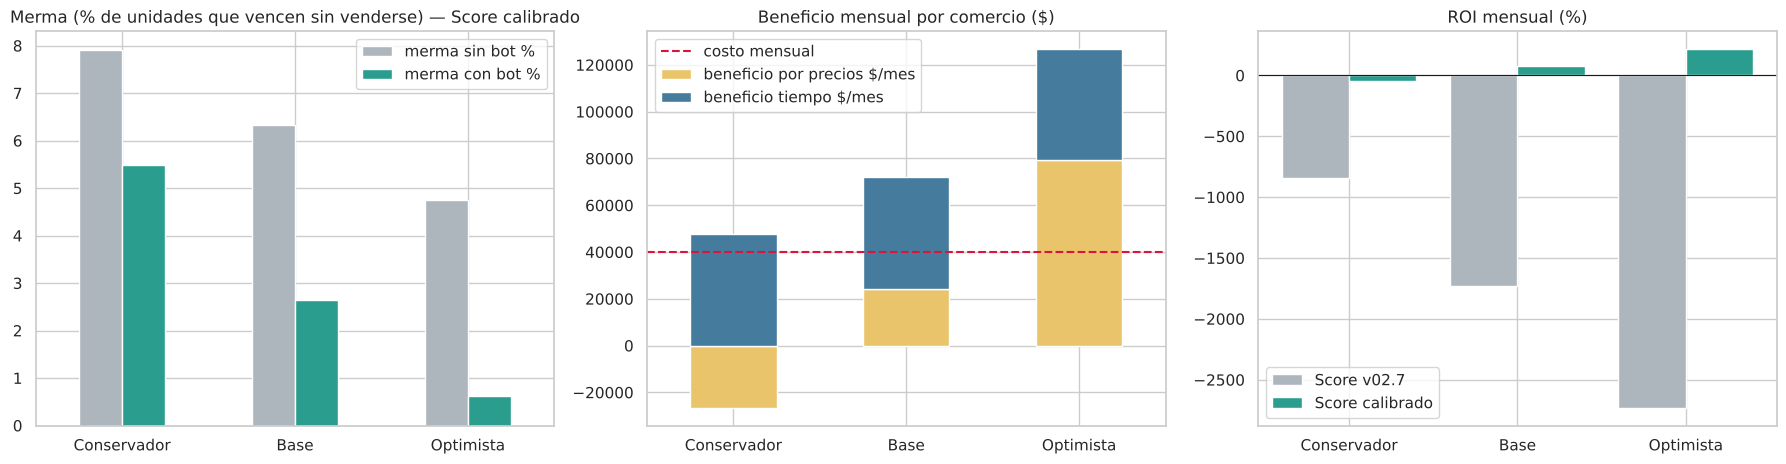

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
roi_tab[["merma sin bot %","merma con bot %"]].plot.bar(ax=ax[0], rot=0, color=["#adb5bd", "#2a9d8f"]); ax[0].set_title("Merma (% de unidades que vencen sin venderse) — Score calibrado")
roi_tab[["beneficio por precios $/mes","beneficio tiempo $/mes"]].plot.bar(stacked=True, ax=ax[1], rot=0, color=["#e9c46a", "#457b9d"])
ax[1].axhline(COSTO_MENSUAL_HERRAMIENTAS, color="crimson", ls="--", label="costo mensual"); ax[1].legend(); ax[1].set_title("Beneficio mensual por comercio ($)")
x = np.arange(3); ax[2].bar(x - .2, roi_B["ROI %"], .4, label="Score v02.7", color="#adb5bd"); ax[2].bar(x + .2, roi_tab["ROI %"], .4, label="Score calibrado", color="#2a9d8f")
ax[2].set_xticks(x); ax[2].set_xticklabels(roi_tab.index); ax[2].axhline(0, color="k", lw=.8); ax[2].legend(); ax[2].set_title("ROI mensual (%)")
for a in ax: a.set_xlabel("")
plt.tight_layout(); plt.show()

### 🔎 Cómo leer estos resultados (con honestidad)
1. **Score v02.7 tal cual**: baja la merma casi a cero, pero en la simulación **resta ganancia en los tres escenarios** (ROI muy negativo). Vende todo, pero a precios tan bajos que no compensa. **No conviene presentar un ROI de esa versión**: conviene presentar la mejora.
2. **Score calibrado**: la merma baja de forma clara y la ganancia por lote cambia **poco** (del orden de cientos de pesos sobre ganancias de decenas de miles por lote) y **depende de la adherencia**: con pocos comerciantes siguiendo el Score es negativa.
3. **El beneficio solo por precios no alcanza, por sí mismo, para pagar las herramientas en el escenario base** (ver fila `ROI % solo precios`). El ROI total positivo depende del **ahorro de tiempo**, que hoy es un **supuesto** (minutos y valor hora inventados para poder calcular). Si al cronometrar el ahorro es menor, el ROI baja.
4. **Entonces, ¿cuál es el argumento fuerte del proyecto?** No es "vendo más caro", es: **(a)** *menos comida tirada* (impacto social y ambiental: ver "unidades rescatadas" y "unidades sin vender candidatas a donación"), **(b)** *tiempo ahorrado* al comerciante y **(c)** *decisiones de precio con datos de la competencia* en vez de a ojo. Es coherente con el puntaje extra de la guía por Innovación Social-Comercial.
5. **La palanca más importante es la adherencia** (que el comerciante haga caso): por eso las **Notificaciones** (opción 4 del menú, hoy pendiente) y acciones de un solo toque valen más que un modelo más sofisticado.

### 4.7 Sensibilidad: ¿de qué depende el ROI? (Score calibrado)
El jurado va a preguntar *"¿y si los comerciantes no te hacen caso?"* o *"¿y si la gente no reacciona al precio?"*. Esta tabla responde: **ROI mensual (%) según adherencia y sensibilidad al precio**.

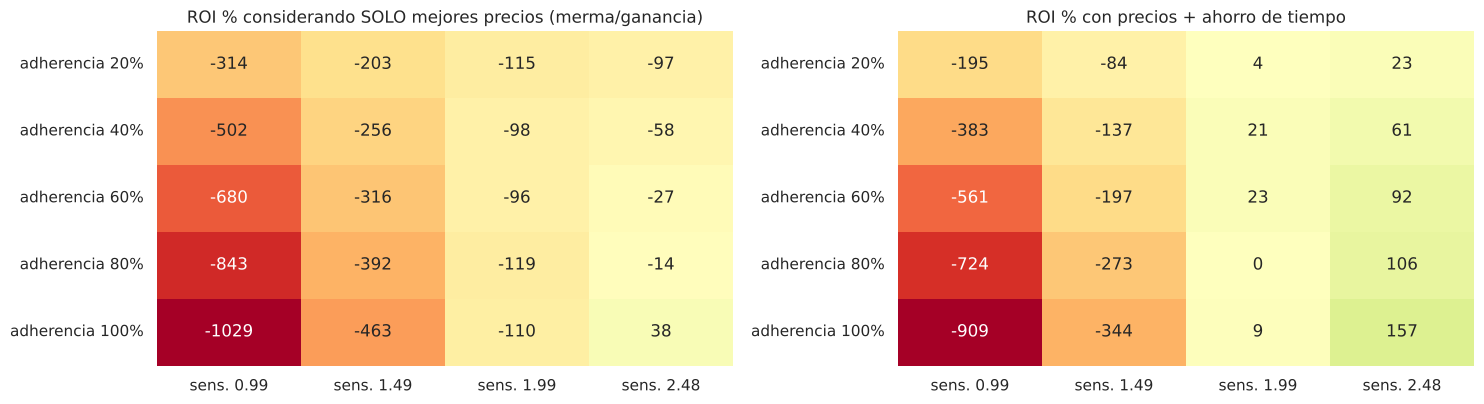

In [15]:
adhs = [0.2, 0.4, 0.6, 0.8, 1.0]; sens = [SENSIBILIDAD * f for f in (0.5, 0.75, 1.0, 1.25)]
cols = [f"sens. {s:.2f}" for s in sens]; filas_ = [f"adherencia {int(a*100)}%" for a in adhs]
grid = pd.DataFrame(index=filas_, columns=cols, dtype=float); grid_precios = grid.copy()
for a, fa in zip(adhs, filas_):
    for s, cs in zip(sens, cols):
        df = simular(a, s, bot="C", reps=2)
        b_precios = (df.ganancia_B - df.ganancia_A).mean() * lotes_mes
        grid_precios.loc[fa, cs] = (b_precios - COSTO_MENSUAL_HERRAMIENTAS) / COSTO_MENSUAL_HERRAMIENTAS * 100
        grid.loc[fa, cs] = (b_precios + beneficio_tiempo - COSTO_MENSUAL_HERRAMIENTAS) / COSTO_MENSUAL_HERRAMIENTAS * 100
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
sns.heatmap(grid_precios, annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=ax[0], cbar=False); ax[0].set_title("ROI % considerando SOLO mejores precios (merma/ganancia)")
sns.heatmap(grid, annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=ax[1], cbar=False); ax[1].set_title("ROI % con precios + ahorro de tiempo")
plt.tight_layout(); plt.show()

### 4.8 Métricas de negocio para el pitch (elegir 1 o 2 y sostenerlas)
Los apuntes piden **1 o 2 métricas que sostengan la solución**. Proponemos:
1. **% de merma** = unidades vencidas sin vender ÷ unidades ingresadas. *Se mide ya* (con `Lotes_Registrados` + `Ventas_Registradas`) y es la que más le importa al comerciante (plata) y al jurado (impacto social).
2. **Ganancia recuperada por lote** = diferencia de ganancia por lote con y sin seguir las recomendaciones. *Es la que evita el error del Score v02.7: bajar el precio no es un logro si se pierde margen.*

*(Satisfacción del cliente: si el jurado la pide, se puede agregar una encuesta de 1 pregunta en el bot — "¿Te sirvió la recomendación de hoy? 👍/👎" — y medir % de 👍.)*

In [16]:
b = sims["Base"]
resumen = pd.DataFrame({
    "Métrica (escenario base, Score calibrado)": ["Merma sin bot", "Merma con Score calibrado", "Reducción de merma",
                "Unidades rescatadas cada 1.000 ingresadas", "Ganancia extra por lote", "ROI mensual"],
    "Valor": [f"{roi_tab.loc['Base','merma sin bot %']:.1f} %", f"{roi_tab.loc['Base','merma con bot %']:.1f} %",
              f"{roi_tab.loc['Base','merma sin bot %'] - roi_tab.loc['Base','merma con bot %']:.1f} puntos",
              f"{(b.vend_B - b.vend_A).sum() / b.cantidad.sum() * 1000:,.0f} un.", f"${roi_tab.loc['Base','ganancia extra/lote $']:,.0f}",
              f"{roi_tab.loc['Base','ROI %']:.0f} %"]})
resumen

,"Métrica (escenario base, Score calibrado)",Valor
0,Merma sin bot,6.3 %
1,Merma con Score calibrado,2.7 %
2,Reducción de merma,3.7 puntos
3,Unidades rescatadas cada 1.000 ingresadas,37 un.
4,Ganancia extra por lote,$783
5,ROI mensual,80 %


## 5. Dashboard (apuntes §4) — vista previa y datos para Looker Studio
Requisitos de los apuntes: **manejable por el cliente**, con **tablas y métricas de negocio**, organizable en pestañas.
La versión final se arma en **Looker Studio** conectando la pestaña `Score_Rescate` (la publica `exportar_dashboard.py` del bot). Acá dejamos una **vista previa** con los mismos indicadores y los CSV de ejemplo.

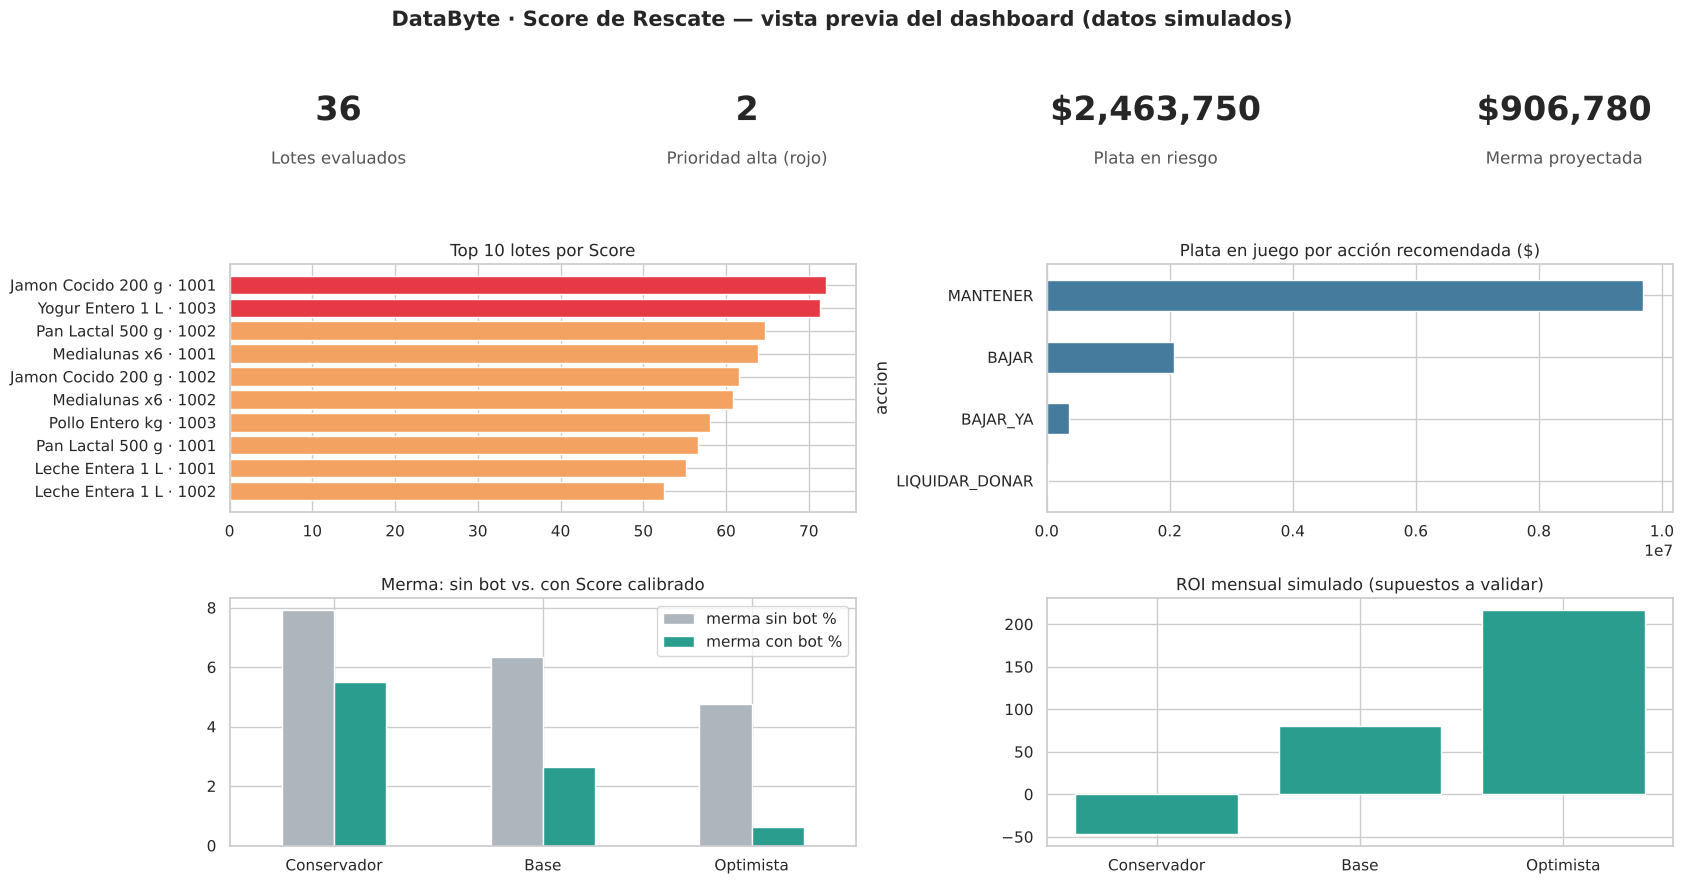

Guardados: dashboard_preview.png, data/score_simulado.csv, data/roi_escenarios.csv


In [17]:
fig = plt.figure(figsize=(17, 9)); gs = fig.add_gridspec(3, 4, height_ratios=[.6, 1.6, 1.6])
ind = MS.indicadores(score.to_dict("records"))
kpi = [("Lotes evaluados", f"{len(score)}"), ("Prioridad alta (rojo)", f"{ind['rojos']}"),
       ("Plata en riesgo", f"${ind['valor_en_riesgo']:,.0f}"), ("Merma proyectada", f"${ind['merma_proyectada_valor']:,.0f}")]
for i, (t, v) in enumerate(kpi):
    a = fig.add_subplot(gs[0, i]); a.axis("off")
    a.text(.5, .62, v, ha="center", fontsize=24, fontweight="bold"); a.text(.5, .15, t, ha="center", fontsize=12, color="#555")
a = fig.add_subplot(gs[1, :2]); top = score.sort_values("score", ascending=False).head(10).iloc[::-1]
a.barh(top.producto + " · " + top.telegram_id, top.score, color=[pal[n] for n in top.nivel]); a.set_title("Top 10 lotes por Score")
a = fig.add_subplot(gs[1, 2:]); score.groupby("accion").valor_en_riesgo.sum().sort_values().plot.barh(ax=a, color="#457b9d"); a.set_title("Plata en juego por acción recomendada ($)")
a = fig.add_subplot(gs[2, :2]); roi_tab[["merma sin bot %","merma con bot %"]].plot.bar(ax=a, rot=0, color=["#adb5bd", "#2a9d8f"]); a.set_title("Merma: sin bot vs. con Score calibrado"); a.set_xlabel("")
a = fig.add_subplot(gs[2, 2:]); a.bar(roi_tab.index, roi_tab["ROI %"], color="#2a9d8f"); a.set_title("ROI mensual simulado (supuestos a validar)")
fig.suptitle("DataByte · Score de Rescate — vista previa del dashboard (datos simulados)", fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, .96]); plt.savefig("dashboard_preview.png", dpi=130); plt.show()

# Archivo equivalente a la pestaña Score_Rescate (columnas = las que publica exportar_dashboard.py).
export = score.assign(fecha_calculo=ahora.strftime("%Y-%m-%d %H:%M:%S"), accion=score.accion_texto)[["fecha_calculo","telegram_id"] + MS.COLUMNAS_SCORE]
export.to_csv("data/score_simulado.csv", index=False)
print("Guardados: dashboard_preview.png, data/score_simulado.csv, data/roi_escenarios.csv")

### Cómo armar el dashboard final en Looker Studio (5 pasos)
1. Correr `python exportar_dashboard.py` en el bot (publica la pestaña **Score_Rescate** en el Google Sheet).
2. En Looker Studio: **Crear → Fuente de datos → Hojas de cálculo de Google** → elegir `DataByte_Rescate_Alimentos` → pestaña `Score_Rescate`.
3. Crear 4 *pestañas/páginas*: **Resumen** (KPIs de arriba), **Lotes** (tabla con filtro por comercio y nivel), **Competencia** (precio actual vs. `precio_referencia`), **Impacto** (merma y ROI).
4. Agregar un **control de filtro** por `telegram_id` (el cliente elige su comercio) y compartir con "Solo lectura".
5. Programar `exportar_dashboard.py` (cada hora/día) para que el tablero se actualice solo.

## 6. Conclusiones y qué falta
* **Qué demostramos**: el Score de Rescate funciona de punta a punta (reglas + índice); un modelo ML de ensamble puede mejorar su *ritmo de venta* (notebook 02) con un procedimiento automatizado; y la simulación del ROI —explícita y auditable— **encontró un defecto real del Score v02.7**: sugiere descuentos más profundos de lo necesario y resta ganancia. La versión **calibrada con la sensibilidad al precio y un piso de costo** lo corrige. Ese es un **insight accionable** para la Etapa 5.
* **Qué NO demostramos todavía**: rendimiento real. Todo depende de datos simulados y de supuestos marcados (`# SUPUESTO`).
* **Para que sea defendible ante el jurado**:
  1. Juntar **4–6 semanas de ventas reales** (`Ventas_Registradas`) y volver a correr los notebooks 01→03.
  2. **Cronometrar** la carga manual vs. el bot y preguntar al comercio su **merma mensual** y el **costo de la hora**; reemplazar los supuestos.
  3. Mostrar **un caso real**: un lote donde el bot recomendó bajar el precio y qué pasó.
  4. Subir al repositorio público los notebooks **sin tokens ni credenciales** (usar `.env` / ejemplos con `xxxx`).